> Versión de portafolio. Se conservan las salidas históricas del trabajo académico. Las rutas absolutas de datos, cuando existían, se sustituyeron por nombres locales. Esta versión no se ha ejecutado de nuevo; consulte README y DATOS.md antes de reproducir.


# Tarea M23-CD Javier Bueno Sanchez

Índice:

1. Objetivo.

2. Variable objetivo.

3. Importación de librerías.

4. Carga del conjunto de datos.

5. Análisis exploratorio de los datos.

6. Preparación de datos.

7. Construcción del modelo.

8. Evaluación.

9. Interpretación.

10. Predicción del nuevo paciente.

11. Conclusiones.

1. Efectuar un análisis de clasificación mediante Árboles de decisión que permita desarrollar un modelo predictivo basado en distintas métricas aplicadas a una base de datos grande.

Problema:   Imagina que eres un investigador médico que recopila datos para un estudio. Has recopilado datos sobre un conjunto de pacientes, todos ellos con la misma enfermedad. Durante su tratamiento, cada paciente ha respondido a uno de los 5 medicamentos, el fármaco A, el fármaco B, el fármaco c, el fármaco X y el Y. 

Parte de tu trabajo consiste en construir un modelo para averiguar qué medicamento podría ser apropiado para un futuro paciente con la misma enfermedad. Los conjuntos de características de este conjunto de datos son la edad, el sexo, la presión arterial y el colesterol de los pacientes, y el objetivo es estudiar el fármaco al que respondió cada paciente. 

Se trata de un ejemplo de clasificación multiclase, y se puede utilizar la parte de entrenamiento del conjunto de datos para construir un árbol de decisión, y luego utilizarlo para predecir la clase de un paciente desconocido, o para prescribirlo a un nuevo paciente.

2. Variable objetivo:

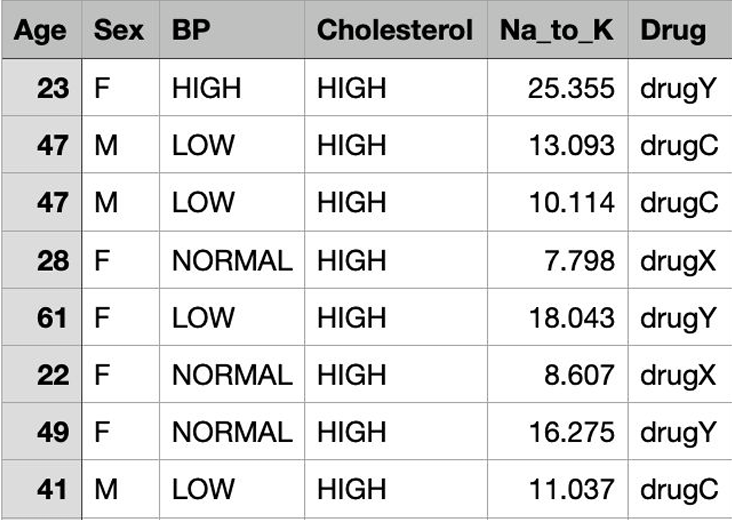

In [139]:
from IPython.display import Image, display

display(Image(filename='/home/javi/Imágenes/variables.png'))

Paso a paso

Cargue la base de datos “drugs.csv” en Python e investigue cómo convertir las variables predictoras cualitativas de esta base a una escala numérica mediante la instrucción “preprocessing.LabelEncoder()”. Por ejemplo, si una variable tiene 3 posibles categorías, deberá cambiar sus resultados a 0, 1 o 2. 

Use el método de Árboles de decisión para generar un modelo predictivo para este problema. Pruebe con los dos criterios vistos en esta lección (Gini y Entropía) y diversos niveles de profundidad. En cada caso elabore un reporte de clasificación detallado. Interprete verbalmente sus indicadores y determine cuál es la mejor opción.

Explique verbalmente las reglas del árbol propuesto al momento de pronosticar.

¿Qué medicamento recomendaría utilizar para un paciente con los siguientes datos? 

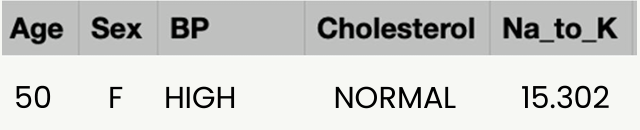

In [140]:
from IPython.display import Image, display

display(Image(filename='/home/javi/Imágenes/paciente m23.png'))

Planteamiento del problema.

Objetivo del negocio:
Determinar qué medicamento sería el más apropiado para un nuevo paciente a partir de sus características clínicas.

Variable objetivo:

Drug.

Variables predictoras:

Age
Sex
BP
Cholesterol
Na_to_K

Tipo de problema:

Clasificación multiclase supervisada.

3. Importación de librerías.

In [141]:
# Manipulación de datos
import pandas as pd
import numpy as np

# Visualización
import matplotlib.pyplot as plt

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

# Métricas
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix)

# Codificación
from sklearn.preprocessing import LabelEncoder

# Advertencias
import warnings
warnings.filterwarnings("ignore")

In [142]:
import pandas
import numpy
import sklearn
import matplotlib
#Verificamos que todas las librerias quedaron instaladas y su version.

print("Pandas:", pd.__version__)
print("NumPy:", numpy.__version__)
print("Scikit-Learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)

Pandas: 2.3.3
NumPy: 2.3.5
Scikit-Learn: 1.7.2
Matplotlib: 3.10.6


4. Carga del conjunto de datos.

In [143]:
df = pd.read_csv("drugs.csv")
# Cargamos el archivo

5. Análisis exploratorio de los datos.

In [144]:
df.head()
# Visualizamos archivo. 

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,HIGH,HIGH,25.355,drugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,drugY


In [145]:
print(f"Filas: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")
# Dimensiones del conjunto de datos.

Filas: 200
Columnas: 6


In [146]:
df.describe()
# Nos muestra valores.

,Age,Na_to_K
count,200.000000,200.000000
mean,44.315000,16.084485
std,16.544315,7.223956
min,15.000000,6.269000
25%,31.000000,10.445500
50%,45.000000,13.936500
75%,58.000000,19.380000
max,74.000000,38.247000


In [147]:
df.isnull().sum()
# Valores nulos por variable.

Age            0
Sex            0
BP             0
Cholesterol    0
Na_to_K        0
Drug           0
dtype: int64

In [148]:
df.info()
# Información general del dataset.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          200 non-null    int64  
 1   Sex          200 non-null    object 
 2   BP           200 non-null    object 
 3   Cholesterol  200 non-null    object 
 4   Na_to_K      200 non-null    float64
 5   Drug         200 non-null    object 
dtypes: float64(1), int64(1), object(4)
memory usage: 9.5+ KB


6. Preparación de datos.

In [149]:
from sklearn.preprocessing import LabelEncoder

le_sex = LabelEncoder()
le_bp = LabelEncoder()
le_chol = LabelEncoder()
le_drug = LabelEncoder()

df["Sex"] = le_sex.fit_transform(df["Sex"])
df["BP"] = le_bp.fit_transform(df["BP"])
df["Cholesterol"] = le_chol.fit_transform(df["Cholesterol"])
df["Drug"] = le_drug.fit_transform(df["Drug"])

print("Sex:", dict(zip(le_sex.classes_, le_sex.transform(le_sex.classes_))))
print("BP:", dict(zip(le_bp.classes_, le_bp.transform(le_bp.classes_))))
print("Cholesterol:", dict(zip(le_chol.classes_, le_chol.transform(le_chol.classes_))))
print("Drug:", dict(zip(le_drug.classes_, le_drug.transform(le_drug.classes_))))

Sex: {'F': np.int64(0), 'M': np.int64(1)}
BP: {'HIGH': np.int64(0), 'LOW': np.int64(1), 'NORMAL': np.int64(2)}
Cholesterol: {'HIGH': np.int64(0), 'NORMAL': np.int64(1)}
Drug: {'drugA': np.int64(0), 'drugB': np.int64(1), 'drugC': np.int64(2), 'drugX': np.int64(3), 'drugY': np.int64(4)}


Las variables categóricas fueron transformadas a valores numéricos mediante LabelEncoder, permitiendo que el algoritmo de Árboles de Decisión pueda procesarlas. La correspondencia entre categorías y valores se conserva para interpretar correctamente las predicciones del modelo.

7. Construcción del modelo.

In [150]:
# Variables predictoras
X = df.drop("Drug", axis=1)

# Variable objetivo
y = df["Drug"]

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Dimensiones de X: (200, 5)
Dimensiones de y: (200,)


In [151]:
# División de datos.
from sklearn.model_selection import train_test_split

# División del conjunto de datos en entrenamiento y prueba.
# test_size = 30% de los datos se guardan para prueba.
# random_state = 42 asegura que el resultado sea reproducible.
# stratify = y mantiene la misma proporción de las clases en los conjuntos de entrenamiento y prueba. 
# De esta forma, ambos representan adecuadamente la distribución original de la base de datos y se evita 
# que una división aleatoria genere muestras poco representativas, lo que podría afectar la evaluación de modelo.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

Entrenamiento: (140, 5)
Prueba: (60, 5)


Primer Árbol Criterio GINI.

In [152]:
from sklearn.tree import DecisionTreeClassifier

# Crear el modelo
tree_gini = DecisionTreeClassifier(criterion="gini", max_depth=4, random_state=42)

# Entrenar
tree_gini.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,4
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [153]:
# Realizar predicciones.
y_pred_gini = tree_gini.predict(X_test)

In [154]:
# Evaluar el modelo.
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print(f"Accuracy: {accuracy_score(y_test, y_pred_gini):.4f}")

print("\nMatriz de confusión")
print(confusion_matrix(y_test, y_pred_gini))

print("\nReporte de clasificación")
print(classification_report(y_test, y_pred_gini))

Accuracy: 0.9833

Matriz de confusión
[[ 7  0  0  0  0]
 [ 1  4  0  0  0]
 [ 0  0  5  0  0]
 [ 0  0  0 16  0]
 [ 0  0  0  0 27]]

Reporte de clasificación
              precision    recall  f1-score   support

           0       0.88      1.00      0.93         7
           1       1.00      0.80      0.89         5
           2       1.00      1.00      1.00         5
           3       1.00      1.00      1.00        16
           4       1.00      1.00      1.00        27

    accuracy                           0.98        60
   macro avg       0.97      0.96      0.96        60
weighted avg       0.99      0.98      0.98        60



8. Evaluación del modelo (criterio Gini)

El árbol de decisión obtuvo una exactitud (Accuracy) del 98.33%, clasificando correctamente 59 de los 60 pacientes del conjunto de prueba. La matriz de confusión muestra únicamente un error de clasificación, mientras que las clases drugC, drugX y drugY fueron identificadas correctamente en todos los casos. Estos resultados indican que el modelo presenta un desempeño muy alto para este conjunto de datos.

In [155]:
# Realizamos el mismo entrenamiento pero cambiamos el criterio.
tree_entropy = DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=42)

tree_entropy.fit(X_train, y_train)

y_pred_entropy = tree_entropy.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred_entropy):.4f}")

print("\nMatriz de confusión")
print(confusion_matrix(y_test, y_pred_entropy))

print("\nReporte de clasificación")
print(classification_report(y_test, y_pred_entropy))

Accuracy: 0.9833

Matriz de confusión
[[ 7  0  0  0  0]
 [ 1  4  0  0  0]
 [ 0  0  5  0  0]
 [ 0  0  0 16  0]
 [ 0  0  0  0 27]]

Reporte de clasificación
              precision    recall  f1-score   support

           0       0.88      1.00      0.93         7
           1       1.00      0.80      0.89         5
           2       1.00      1.00      1.00         5
           3       1.00      1.00      1.00        16
           4       1.00      1.00      1.00        27

    accuracy                           0.98        60
   macro avg       0.97      0.96      0.96        60
weighted avg       0.99      0.98      0.98        60



9. Comparativa de criterios.

In [156]:
# Creamos una tabla comparativa de los dos criterios.

comparativa = pd.DataFrame({"Modelo": ["Árbol de Decisión", "Árbol de Decisión"],
    "Criterio": ["Gini", "Entropía"], "Accuracy": [
        accuracy_score(y_test, y_pred_gini),accuracy_score(y_test, y_pred_entropy)]})

# Formateamos el Accuracy como porcentaje.
comparativa["Accuracy"] = comparativa["Accuracy"].map(lambda x: f"{x:.2%}")

comparativa

,Modelo,Criterio,Accuracy
0,Árbol de Decisión,Gini,98.33%
1,Árbol de Decisión,Entropía,98.33%


Ambos criterios de división obtuvieron un desempeño idéntico sobre el conjunto de prueba, alcanzando una exactitud del 98.33%. Para este conjunto de datos no se observan diferencias significativas entre utilizar el índice Gini o la Entropía como criterio de partición.

Visualizacion de arbol.

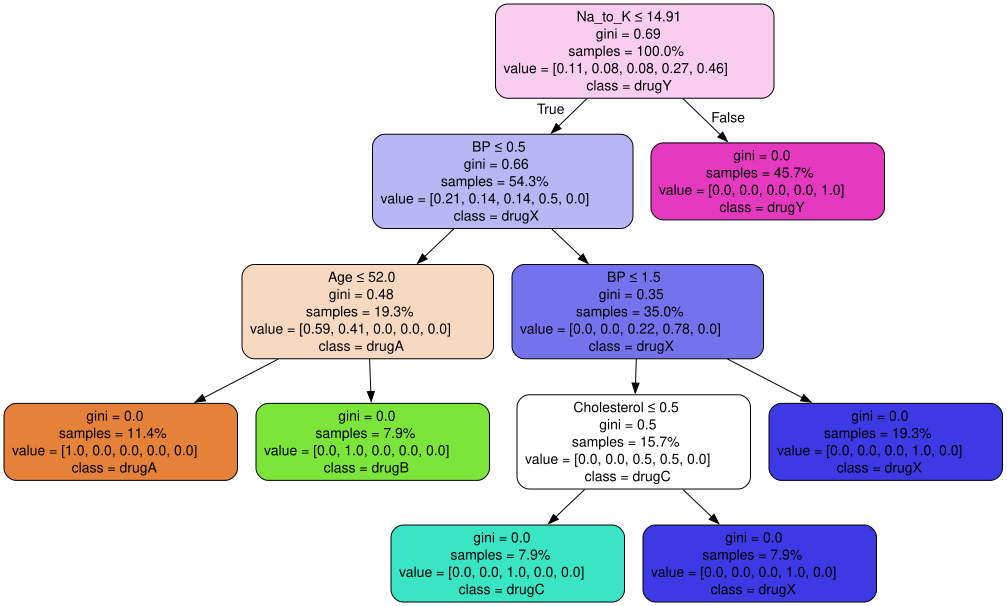

In [157]:
# Importamos graphviz para la visualizacion de arboles.
from sklearn.tree import export_graphviz
import graphviz

# Creaoms archivo 
dot_data = export_graphviz(tree_gini, out_file=None, feature_names=X.columns, class_names=le_drug.classes_,
    filled=True, rounded=True, special_characters=True, impurity=True, proportion=True, precision=2)

# Creamos grafico.
graph = graphviz.Source(dot_data)

graph.format = "png"
graph

10. Predicción del nuevo paciente.

In [158]:
# Creamos el DataFrame con los datos del nuevo paciente.
nuevo_paciente = pd.DataFrame([[50, 0, 0, 1, 15.302]], columns=X.columns)

# Utilizamos el modelo definido con estos datos nuevos.
prediccion = tree_gini.predict(nuevo_paciente)

medicamento = le_drug.inverse_transform(prediccion)

print("Medicamento predicho:", medicamento[0])

Medicamento predicho: drugY


Conclusión predicción nuevo paciente.

Se evaluó un paciente de 50 años, sexo masculino, con presión arterial alta (HIGH), colesterol alto (HIGH) y una relación Na_to_K de 15.302. El modelo de Árbol de Decisión predijo que el medicamento más adecuado es drugY, de acuerdo con las reglas aprendidas a partir de los datos de entrenamiento.

11. Conclusiones.

- Se implementó correctamente un modelo de Árbol de Decisión utilizando Scikit-learn para clasificar el medicamento recomendado a partir de las características clínicas de los pacientes.
Los criterios de división Gini y Entropía obtuvieron el mismo desempeño sobre el conjunto de prueba, alcanzando una exactitud del 98.33%, lo que indica que ambos son igualmente adecuados para este conjunto de datos.

- La visualización del árbol permitió interpretar las reglas de decisión utilizadas por el modelo, facilitando comprender cómo cada variable influye en la clasificación.

- Finalmente, el modelo fue utilizado para predecir el medicamento recomendado para un nuevo paciente, obteniendo como resultado drugY, demostrando la capacidad del algoritmo para apoyar procesos de clasificación supervisada.

Comentarios adicionales.

El árbol de decisión comienza evaluando la relación sodio/potasio (Na_to_K), ya que es la variable que mejor separa a los pacientes. Posteriormente utiliza variables como la presión arterial, la edad y el colesterol para refinar la clasificación. En este modelo, la variable Sex no interviene en las decisiones, lo que indica que no aporta capacidad adicional de clasificación para este conjunto de datos.